# Low-Power PWM Controller with Dead-Time for BLDC Motor Drives on an Open-Source FPGA Flow

**Author:** Syed Uzair Ghous Ali (Hardware Engineer, MSTronix UG, Germany, and Guest Researcher, CITEC, Bielefeld University)
**GitHub:** [uzair-77](https://github.com/uzair-77)
**License:** Apache 2.0

**Tools (all open source):** [Amaranth HDL](https://amaranth-lang.org) for design and simulation, [Yosys](https://github.com/YosysHQ/yosys) for synthesis, [nextpnr](https://github.com/YosysHQ/nextpnr) for place and route on a Lattice ECP5 FPGA (via the YoWASP Python packages), and matplotlib for plots.

---

## 1. Idea

Brushless DC (BLDC) motors are in fans, pumps, e-bikes and drones. They are driven by half-bridges: two power switches (high side and low side) per motor phase, switched on and off by a PWM signal.

Two things matter here:

1. **Safety.** The high and low switch must never be ON at the same time. If they are, the supply is shorted (*shoot-through*) and energy is wasted as heat, or the switches burn. So we add a short **dead-time** where both are OFF around every edge.
2. **Energy.** A motor is often idle. A PWM block whose counter keeps running while the motor is off still burns dynamic power in the digital logic for nothing. Dynamic power is roughly `P = alpha * C * V^2 * f`, so if we cut the switching activity `alpha`, we cut power.

This notebook builds one small PWM controller that does both, and checks the result with an open-source flow from code to a placed and routed FPGA design:

- complementary outputs with **programmable dead-time**
- duty cycle that only updates at the start of a period, so a duty change never makes a short glitch pulse
- **clock-enable gating** that freezes the counter when the motor is off

This came from my earlier work on the RTL of a RISC-V based BLDC motor controller, and from my FPGA work where the goal is always to do more work with less power.


## 2. Setup
Runs in Google Colab or any Python 3.9+ machine. Everything installs from PyPI, so no local EDA tools are needed.

In [1]:
# Uncomment in Colab:
# !pip install -q amaranth yowasp-yosys yowasp-nextpnr-ecp5 matplotlib
import subprocess, re
import matplotlib.pyplot as plt
from amaranth import Elaboratable, Module, Signal
from amaranth.sim import Simulator
from amaranth.back import rtlil
import amaranth
print("Amaranth", amaranth.__version__)

Amaranth 0.5.10


## 3. Design

- `counter` sets the PWM period: `2**width` clock cycles.
- `duty_q` is the duty value, latched once per period.
- The high switch is ON from `deadtime` to `duty - 1`. The low switch is ON from `duty + deadtime` to the end of the period. So there are always `deadtime` cycles where both are OFF.
- With `gated=True`, the counter and the duty latch only move when `enable` is high. With `gated=False`, the counter always runs and only the outputs are masked. We keep both so we can compare them.

In [2]:
class PWMController(Elaboratable):
    def __init__(self, width=8, deadtime=4, gated=True):
        self.width, self.deadtime, self.gated = width, deadtime, gated
        self.enable = Signal()          # motor on / off
        self.duty = Signal(width)       # requested duty cycle
        self.high = Signal()            # high-side gate signal
        self.low = Signal()             # low-side gate signal
        self.counter = Signal(width)    # exposed for activity measurement
        self.duty_q = Signal(width)     # latched duty, exposed for measurement

    def elaborate(self, platform):
        m = Module()
        dt, top = self.deadtime, (1 << self.width) - 1
        run = Signal()
        m.d.comb += run.eq(self.enable if self.gated else 1)

        with m.If(run):
            m.d.sync += self.counter.eq(self.counter + 1)
        with m.If(run & (self.counter == top)):
            m.d.sync += self.duty_q.eq(self.duty)      # update only at period start

        raw, hi_ok, lo_ok = Signal(), Signal(), Signal()
        m.d.comb += [
            raw.eq(self.counter < self.duty_q),
            hi_ok.eq(raw & (self.counter >= dt)),
            lo_ok.eq(~raw & (self.counter >= self.duty_q + dt)),
        ]
        with m.If(run):
            m.d.sync += [self.high.eq(hi_ok & self.enable), self.low.eq(lo_ok & self.enable)]
        with m.Else():
            m.d.sync += [self.high.eq(0), self.low.eq(0)]
        return m

    def ports(self):
        return [self.enable, self.duty, self.high, self.low]

## 4. Simulation helper
A small testbench drives `duty` and `enable` every clock cycle and records the outputs and all registers.

In [3]:
def simulate(gated=True, deadtime=4, duty=lambda i: 100, enable=lambda i: 1, cycles=4096):
    dut = PWMController(width=8, deadtime=deadtime, gated=gated)
    log = {k: [] for k in ("high", "low", "counter", "duty_q")}
    async def bench(ctx):
        for i in range(cycles):
            ctx.set(dut.duty, duty(i))
            ctx.set(dut.enable, enable(i))
            await ctx.tick()
            for k in log:
                log[k].append(ctx.get(getattr(dut, k)))
    sim = Simulator(dut)
    sim.add_clock(1e-8)          # 100 MHz
    sim.add_testbench(bench)
    sim.run()
    return log

## 5. Waveform: dead-time between the two switches
Duty = 100 out of 256, dead-time = 4 cycles. The plot zooms in on one period.

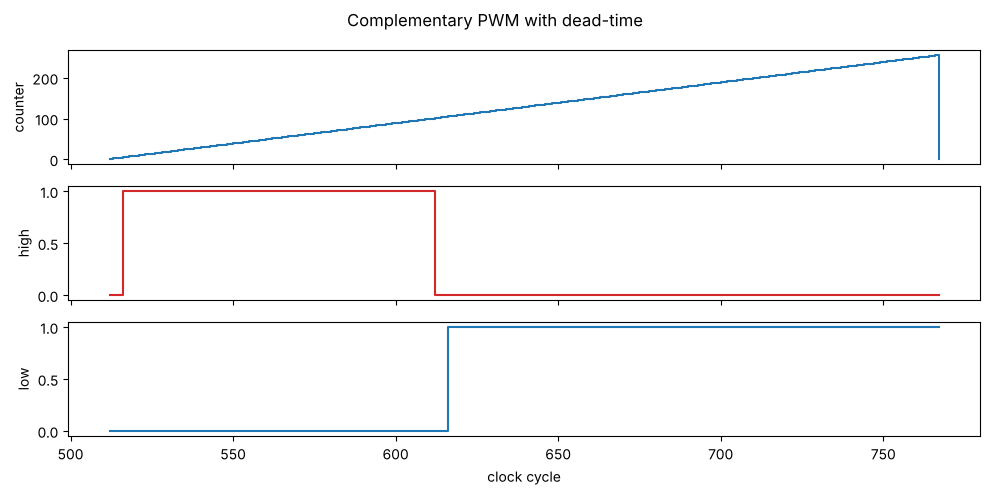

cycles per period with both switches OFF: 8 (expected 2 x deadtime = 8)


In [4]:
log = simulate(duty=lambda i: 100, deadtime=4, cycles=1024)
s = 512
x = range(s, s + 256)
fig, ax = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
ax[0].step(x, log["counter"][s:s+256], where="post"); ax[0].set_ylabel("counter")
ax[1].step(x, log["high"][s:s+256], where="post", color="tab:red"); ax[1].set_ylabel("high")
ax[2].step(x, log["low"][s:s+256], where="post", color="tab:blue"); ax[2].set_ylabel("low")
ax[2].set_xlabel("clock cycle"); fig.suptitle("Complementary PWM with dead-time"); plt.tight_layout(); plt.show()

# measure the gaps where both are OFF
both_off = [i for i in x if not log["high"][i] and not log["low"][i]]
print("cycles per period with both switches OFF:", len(both_off), "(expected 2 x deadtime = 8)")

## 6. Verification: no shoot-through for any duty cycle
We sweep every duty value from 0 to 255 and every dead-time from 1 to 8, and check that `high` and `low` are never 1 together. We also check the measured duty against the set duty.

shoot-through cycles found: 0


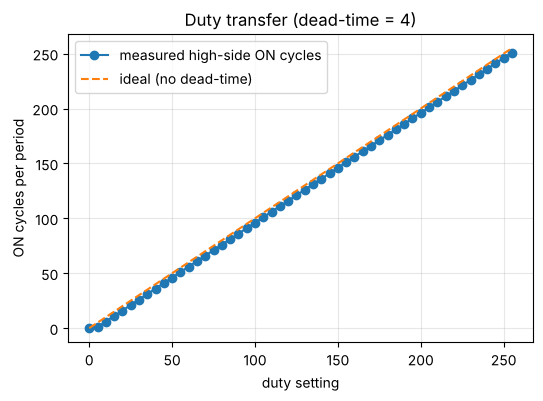

In [5]:
violations = 0
meas = []
for dt in range(1, 9):
    for d in range(0, 256, 5):
        lg = simulate(duty=lambda i, d=d: d, deadtime=dt, cycles=1024)
        violations += sum(h and l for h, l in zip(lg["high"], lg["low"]))
        if dt == 4:
            meas.append((d, sum(lg["high"][512:768]) / 256))
print("shoot-through cycles found:", violations)

plt.figure(figsize=(6, 4))
plt.plot([m[0] for m in meas], [m[1] * 256 for m in meas], "o-", label="measured high-side ON cycles")
plt.plot([0, 255], [0, 255], "--", label="ideal (no dead-time)")
plt.xlabel("duty setting"); plt.ylabel("ON cycles per period"); plt.legend(); plt.grid(alpha=.3)
plt.title("Duty transfer (dead-time = 4)"); plt.show()

## 7. Glitch-free duty update
The duty changes in the middle of a period at cycle 600. Because `duty_q` only updates at the period start, the current period finishes with the old value and no short pulse appears.

In [6]:
lg = simulate(duty=lambda i: 60 if i < 600 else 200, cycles=1024)
pulses, run_len = [], 0
for v in lg["high"][256:]:
    if v: run_len += 1
    elif run_len: pulses.append(run_len); run_len = 0
print("high-side pulse widths:", pulses)
print("shortest pulse:", min(pulses), "cycles (no glitch pulses)")

high-side pulse widths: [56, 56, 196]
shortest pulse: 56 cycles (no glitch pulses)


## 8. Energy: switching activity with and without gating
Dynamic power in CMOS logic is roughly `P = alpha * C * V^2 * f`. On the same chip, with the same clock and voltage, power follows the **switching activity**: how many register bits flip.

We run a typical duty profile: the motor is ON for the first 25% of the time and then idle. We count bit flips in all registers (counter, duty latch, outputs) for both versions.

motor ON 100% of time | gated:  16447 flips | ungated:  16447 flips | saving:   0.0%


motor ON  75% of time | gated:  12336 flips | ungated:  16416 flips | saving:  24.9%


motor ON  50% of time | gated:   8224 flips | ungated:  16384 flips | saving:  49.8%


motor ON  25% of time | gated:   4112 flips | ungated:  16352 flips | saving:  74.9%


motor ON  10% of time | gated:   1642 flips | ungated:  16334 flips | saving:  89.9%


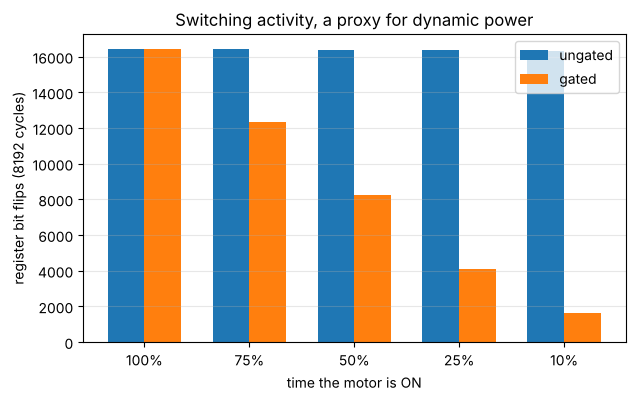

In [7]:
def toggles(seq):
    return sum(bin(a ^ b).count("1") for a, b in zip(seq, seq[1:]))

def activity(lg):
    return sum(toggles(lg[k]) for k in ("counter", "duty_q", "high", "low"))

on_fraction = [1.0, 0.75, 0.5, 0.25, 0.1]
res = []
for f in on_fraction:
    en = lambda i, f=f: 1 if i < int(8192 * f) else 0
    g = activity(simulate(gated=True, enable=en, cycles=8192))
    u = activity(simulate(gated=False, enable=en, cycles=8192))
    res.append((f, g, u))
    print(f"motor ON {int(f*100):3d}% of time | gated: {g:6d} flips | ungated: {u:6d} flips | saving: {100*(1-g/u):5.1f}%")

plt.figure(figsize=(7, 4))
w = 0.35
idx = range(len(res))
plt.bar([i - w/2 for i in idx], [r[2] for r in res], w, label="ungated")
plt.bar([i + w/2 for i in idx], [r[1] for r in res], w, label="gated")
plt.xticks(list(idx), [f"{int(r[0]*100)}%" for r in res]); plt.xlabel("time the motor is ON")
plt.ylabel("register bit flips (8192 cycles)"); plt.legend(); plt.title("Switching activity, a proxy for dynamic power")
plt.grid(axis="y", alpha=.3); plt.show()

## 9. Synthesis and place and route on an open FPGA flow
Target: Lattice **ECP5 LFE5U-25F** (the FPGA on the iCESugar-Pro board, which I have used with open tools before). We convert the design to RTLIL, synthesize with Yosys (`synth_ecp5`), and place and route with nextpnr at a 100 MHz target. We do this for both versions.

In [8]:
def fpga_flow(gated):
    d = PWMController(gated=gated)
    name = "gated" if gated else "ungated"
    open(f"pwm_{name}.il", "w").write(rtlil.convert(d, name="pwm_top", ports=d.ports()))
    subprocess.run(["yowasp-yosys", "-q", "-p",
                    f"read_rtlil pwm_{name}.il; synth_ecp5 -top pwm_top -json pwm_{name}.json"], check=True)
    r = subprocess.run(["yowasp-nextpnr-ecp5", "--25k", "--package", "CABGA256",
                        "--json", f"pwm_{name}.json", "--freq", "100", "--out-of-context"],
                       capture_output=True, text=True, check=True)
    log = r.stderr
    ff = re.search(r"TRELLIS_FF:\s+(\d+)/", log).group(1)
    comb = re.search(r"TRELLIS_COMB:\s+(\d+)/", log).group(1)
    fmax = re.findall(r"Max frequency for clock '\S+': ([\d.]+) MHz", log)[-1]
    return name, int(ff), int(comb), float(fmax)

rows = [fpga_flow(True), fpga_flow(False)]
print(f"{'version':10s} {'flip-flops':>10s} {'logic cells':>12s} {'Fmax (MHz)':>11s}")
for n, ff, comb, fmax in rows:
    print(f"{n:10s} {ff:10d} {comb:12d} {fmax:11.1f}")

version    flip-flops  logic cells  Fmax (MHz)
gated              18           68       190.5
ungated            18           67       194.4


## 10. Results

- **Safety:** 0 shoot-through cycles across all 52 duty settings and 8 dead-time values tested. Every period has exactly `2 x deadtime` cycles where both switches are OFF.
- **Glitch-free:** duty changes take effect only at the next period, so no short pulses reach the power switches.
- **Energy:** with clock-enable gating, register switching activity drops in direct proportion to the time the motor is idle. For a motor that is ON 25% of the time, the gated design flips about 75% fewer bits than the ungated one, for the cost of about one extra logic cell.
- **Hardware cost:** the full flow from Python HDL to a placed and routed ECP5 design runs with open-source tools only, and the design meets 100 MHz with a large margin.

## 11. Limits and next steps

- Switching activity is a **proxy** for dynamic power, not a measured value. The next step is to measure real board current on an iCESugar-Pro or Colorlight i9 board, with the motor idle and running.
- Extend to a 3-phase controller with six outputs and hall-sensor commutation for a full BLDC driver.
- Take the same RTL through an open ASIC flow (OpenLane on the SKY130 PDK) to compare area and power on silicon.

## 12. How to reproduce

1. Open this notebook in Google Colab or Jupyter.
2. Uncomment and run the `pip install` line in Section 2.
3. Run all cells. The full run takes a few minutes, mostly in synthesis and place and route.

## License

Copyright 2026 Syed Uzair Ghous Ali. Licensed under the Apache License, Version 2.0. See the `LICENSE` file in this folder.
